# 00 · Démo : vérifier que tout fonctionne

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/00_setup/demo_solutions.ipynb)

Ce notebook vérifie ton installation, sur Colab comme sur ton ordinateur. Lance **Exécuter tout** (*Run all*) : il doit aller jusqu'au bout sans erreur.

| Étape | Ce que tu vérifies |
|---|---|
| 1. Setup | Python, les bibliothèques, la graine aléatoire |
| 2. `wbm.check` | la vérification de tes réponses : un nombre, une fraction, une expression, un intervalle |
| 3. SymPy | le calcul symbolique, qui vérifie tes calculs à la main |
| 4. Un graphique | une fonction et sa tangente avec matplotlib |
| 5. `mymath` | ta propre librairie, construite chapitre après chapitre |

## 1. Setup

Chaque notebook du workbook commence par **la même cellule**. Sur Colab, elle monte ton Google Drive, récupère la dernière version du dépôt (`git pull`) ou le clone la première fois, puis appelle `wbm.setup()`. En local, elle retrouve simplement le dossier du dépôt.

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## 2. Vérifier une réponse sans voir la solution

Dans les chapitres, tu calcules d'abord **à la main**, sur papier, puis tu tapes ta réponse dans le notebook. `wbm.check("ID", ta_réponse)` te dit si elle est juste, **sans jamais afficher la bonne réponse** : seule une empreinte chiffrée de la solution est dans le dépôt. Quand c'est faux, le message essaie de dire où chercher (signe, facteur 2, fraction à l'envers…).

Quatre exemples, déjà remplis avec la bonne réponse. Exécute-les, puis **change une valeur** pour voir un message d'erreur.

**Démo 1 (un nombre).** Combien vaut $2^{10}$ ?

In [2]:
wbm.record("DEMO.1", 2**10, mistakes={"tu as calculé 2 × 10, pas 2 puissance 10": 20})

WBM_ANSWER {"hash": "887eec2cb84ea0912b278386d00c46edf751d1c2fef981bfbd159bb3a4147646", "id": "DEMO.1", "kind": "int", "magnitude": 3, "mistakes": {"763aba5e1f5134077cda45f6215aa6e122a491e5aad5aaae01b66f891ed3df46": "tu as calculé 2 × 10, pas 2 puissance 10"}, "sign": 1}
📝 Ex DEMO.1 : réponse enregistrée (int).


In [3]:
answer_1 = 1024
wbm.check("DEMO.1", answer_1)

✅ Ex DEMO.1 : C'est ça !


**Démo 2 (une fraction exacte).** Combien vaut $\dfrac{1}{2} + \dfrac{1}{3}$ ? Une fraction s'écrit comme un texte, entre guillemets : `"5/6"`. Essaie aussi `"10/12"`, `0.8333` et `"2/5"`.

In [4]:
from fractions import Fraction
wbm.record("DEMO.2", Fraction(1, 2) + Fraction(1, 3), kind="fraction",
           mistakes={"on n'additionne pas les numérateurs et les dénominateurs entre eux": "2/5"})

WBM_ANSWER {"hash": "18413aff7c77366fe5ec42c013eec21e51ecc36a38b7a5ca5b5c8a28ea00b634", "id": "DEMO.2", "kind": "fraction", "mistakes": {"a4f2bb1e79ce8a561c73aec8c971e331c27cc3227ccd92b00c03d7417fddb0e2": "on n'additionne pas les numérateurs et les dénominateurs entre eux"}, "sign": 1}
📝 Ex DEMO.2 : réponse enregistrée (fraction).


In [5]:
answer_2 = "5/6"
wbm.check("DEMO.2", answer_2)

✅ Ex DEMO.2 : Parfait !


**Démo 3 (une expression).** Quelle est la dérivée de $f(x) = x^3$ ? Une expression s'écrit comme en Python, entre guillemets : `"3*x**2"`. Les écritures `"3x^2"` et `"3*x²"` sont acceptées aussi. Essaie `"x**2"` ou `"-3*x**2"`.

In [6]:
wbm.record("DEMO.3", "3*x**2", kind="expr", variables=("x",),
           mistakes={"l'exposant baisse de 1, et l'ancien exposant passe devant": "x**2"})

WBM_ANSWER {"hash": "4c271925cd643c9146b507b35b475ba8ae04d844bdeb782780310d874a6d7f4e", "id": "DEMO.3", "kind": "expr", "mistakes": {"4f27bbbf0f14c7125203422c93d8aa2740a8bd6bdab7cdbff52283a5748648d7": "l'exposant baisse de 1, et l'ancien exposant passe devant"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex DEMO.3 : réponse enregistrée (expr).


In [7]:
answer_3 = "3*x**2"
wbm.check("DEMO.3", answer_3)

✅ Ex DEMO.3 : Bravo !


**Démo 4 (un intervalle).** Pour quels réels $x$ a-t-on $x^2 \le 4$ ? Un intervalle s'écrit en notation française `"[-2 ; 2]"` (ou anglaise `"[-2, 2]"`). Essaie `"]-2 ; 2["`.

In [8]:
wbm.record("DEMO.4", "[-2 ; 2]", kind="interval",
           mistakes={"l'inégalité est large : -2 et 2 sont-ils solutions ?": "]-2 ; 2["})

WBM_ANSWER {"hash": "b667d278eea6d4677344b1129d594109a8fbb8bfc524fec77283feb0d81d81e7", "id": "DEMO.4", "kind": "interval", "mistakes": {"6973d62333b19ea2fa48f2bb4fa7e0874fc5c841d602d13094dbe036db4a40f3": "l'inégalité est large : -2 et 2 sont-ils solutions ?"}}
📝 Ex DEMO.4 : réponse enregistrée (interval).


In [9]:
answer_4 = "[-2 ; 2]"
wbm.check("DEMO.4", answer_4)

✅ Ex DEMO.4 : Exact !


## 3. SymPy : vérifier un calcul à la main

SymPy fait du **calcul symbolique** : il manipule les expressions comme sur une feuille, sans approximation. Dans ce workbook, il sert à **vérifier** ce que tu as calculé à la main, jamais à le faire à ta place.

In [10]:
import sympy as sp

x = sp.Symbol("x")
f = x**2 * sp.exp(-x)
print("f(x)        =", f)
print("f'(x)       =", sp.factor(sp.diff(f, x)))
print("f'(x) = 0 si x ∈", sp.solve(sp.diff(f, x), x))
print("∫ f sur [0, +∞[ =", sp.integrate(f, (x, 0, sp.oo)))

f(x)        = x**2*exp(-x)
f'(x)       = -x*(x - 2)*exp(-x)


f'(x) = 0 si x ∈ [0, 2]


∫ f sur [0, +∞[ = 2


## 4. Un graphique : une fonction et sa tangente

La tangente à la courbe de $f$ au point d'abscisse $a$ a pour équation $y = f(a) + f'(a)(x - a)$ : c'est la meilleure approximation affine de $f$ près de $a$ (chapitre R7).

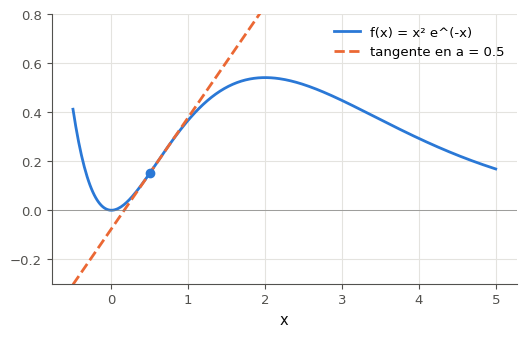

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def f(x):
    return x**2 * np.exp(-x)

def df(x):
    return (2 * x - x**2) * np.exp(-x)

a = 0.5
xs = np.linspace(-0.5, 5, 300)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(xs, f(xs), label="f(x) = x² e^(-x)")
ax.plot(xs, f(a) + df(a) * (xs - a), linestyle="--", label=f"tangente en a = {a}")
ax.scatter([a], [f(a)], zorder=3)
ax.set_ylim(-0.3, 0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.set_xlabel("x")
ax.legend()
plt.show()

## 5. `mymath`, ta librairie

Au fil des chapitres, tu écris ta propre librairie de maths dans `mon_travail/mymath/` : pivot de Gauss, méthode de Newton, valeurs propres, échantillonnage… Les tests la comparent à des bibliothèques de confiance (NumPy, SciPy, SymPy).

Pour la créer : `python tools/start_chapter.py --init` (sur Colab, voir `00_setup/COLAB.md`). Tant qu'elle n'existe pas, la cellule ci-dessous affiche ⏳ au lieu de planter.

In [12]:
mymath = wbm.load_mymath("ref")
print("mymath._example.mean([1, 2, 3, 4]) =", mymath._example.mean([1, 2, 3, 4]))

mymath._example.mean([1, 2, 3, 4]) = 2.5


## C'est prêt

Si tout s'est exécuté jusqu'ici, ton environnement fonctionne. Suite : le test de positionnement (`python tools/start_chapter.py POS`) puis le chapitre R0, en parallèle du chapitre 0A de workbookIA (voir le README, « Ordre de travail commun »).